In [22]:
import torch
import matplotlib.pyplot as plt

from ngo.trainingdata.GRF import ManufacturedSolution
from ngo.testproblems.steadydiffusion.manufacturedsolutions import *
from ngo.numericalanalysis.quadrature import GaussLegendreQuadrature

In [23]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
N_samples = 100
n_x = 100
n_y = 100
n_z = 100
N = n_x * n_y * n_z
Q_x = 99
Q_y = 99
Q_z = 99

n_elements_x = 3
n_elements_y = 3
n_elements_z = 3

quadrature_x = GaussLegendreQuadrature(Q=[Q_x], n_elements=[n_elements_x])
quadrature_y = GaussLegendreQuadrature(Q=[Q_y], n_elements=[n_elements_y])
quadrature_z = GaussLegendreQuadrature(Q=[Q_z], n_elements=[n_elements_z])

x = torch.tensor(quadrature_x.xi.reshape(quadrature_x.xi.shape[0],), device='cuda', dtype=torch.float32)
y = torch.tensor(quadrature_y.xi.reshape(quadrature_y.xi.shape[0],), device='cuda', dtype=torch.float32)
z = torch.tensor(quadrature_z.xi.reshape(quadrature_z.xi.shape[0],), device='cuda', dtype=torch.float32)

X = x,y


In [31]:
N_samples = 1000
lambda_min = torch.tensor([0.1,0.1], device='cuda', dtype=torch.float32)
lambda_max = torch.tensor([0.1,0.1], device='cuda', dtype=torch.float32)
d = len(lambda_min)
b_min_u = -1 #torch.tensor([1], device='cuda', dtype=torch.float64)
b_max_u = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_min_u = 0 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_max_u  = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
device = 'cuda'
dtype = torch.float32
n = (3,3)

In [32]:
u = ManufacturedSolution(N_samples, d, lambda_min, lambda_max, b_min_u, b_max_u, c_min_u, c_max_u, device, dtype, n)

In [33]:
torch.cuda.empty_cache()
u.forward(X)

tensor([[[-0.6665, -0.6655, -0.6630,  ..., -0.2225, -0.2469, -0.2601],
         [-0.6727, -0.6718, -0.6694,  ..., -0.2196, -0.2441, -0.2573],
         [-0.6835, -0.6827, -0.6806,  ..., -0.2143, -0.2389, -0.2522],
         ...,
         [-0.5186, -0.5197, -0.5213,  ..., -0.5513, -0.5600, -0.5644],
         [-0.5003, -0.5012, -0.5022,  ..., -0.5633, -0.5719, -0.5763],
         [-0.4901, -0.4908, -0.4915,  ..., -0.5695, -0.5781, -0.5824]],

        [[ 1.2865,  1.2594,  1.2092,  ..., -0.0530, -0.0600, -0.0633],
         [ 1.2711,  1.2438,  1.1934,  ..., -0.0355, -0.0424, -0.0457],
         [ 1.2420,  1.2145,  1.1637,  ..., -0.0037, -0.0106, -0.0139],
         ...,
         [-0.1138, -0.1326, -0.1668,  ...,  0.8837,  0.8730,  0.8669],
         [-0.1459, -0.1644, -0.1982,  ...,  0.9132,  0.9020,  0.8956],
         [-0.1633, -0.1817, -0.2152,  ...,  0.9293,  0.9178,  0.9112]],

        [[-1.6034, -1.6050, -1.6071,  ..., -0.0291, -0.0053,  0.0076],
         [-1.5996, -1.6017, -1.6045,  ..., -0

In [18]:
b_min_theta = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
b_max_theta = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_min_theta = 0 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_max_theta  = 0.2 #torch.tensor([1], device='cuda', dtype=torch.float64)

In [19]:
theta = ManufacturedSolution(N_samples, d, lambda_min, lambda_max, b_min_theta, b_max_theta, c_min_theta, c_max_theta, device, dtype, n)

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, dtype=self.dtype, device=self.device)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, dtype=self.dtype, device=self.device)


In [23]:
theta.forward(X)

tensor([[[ 9.9775, 10.0110, 10.0661,  ..., 10.2623, 10.1853, 10.1396],
         [10.0128, 10.0465, 10.1021,  ..., 10.3004, 10.2231, 10.1773],
         [10.0708, 10.1050, 10.1613,  ..., 10.3633, 10.2856, 10.2395],
         ...,
         [ 9.9081,  9.9391,  9.9894,  ..., 10.4337, 10.3710, 10.3331],
         [ 9.8438,  9.8742,  9.9236,  ..., 10.3738, 10.3112, 10.2734],
         [ 9.8052,  9.8353,  9.8840,  ..., 10.3375, 10.2749, 10.2371]]],
       device='cuda:0')

In [24]:
f = Forcing(theta, u)

In [25]:
f.forward(X)

tensor([[[  496.5850,   532.9717,   598.5029,  ...,  -739.4269,
           -712.3668,  -696.9775],
         [  455.1108,   491.9799,   558.4872,  ...,  -760.3333,
           -735.1362,  -720.7352],
         [  377.9579,   415.6338,   483.7915,  ...,  -796.4226,
           -774.7764,  -762.2626],
         ...,
         [ -547.5464,  -535.6395,  -511.5400,  ...,  -931.4052,
           -950.8219,  -959.7395],
         [ -522.1503,  -509.7954,  -484.9389,  ...,  -956.4892,
           -975.7303,  -984.5364],
         [ -507.9584,  -495.3690,  -470.1190,  ...,  -969.1199,
           -988.2359,  -996.9665]],

        [[  933.6241,   937.8505,   943.2198,  ...,  1236.8375,
           1233.3782,  1229.8191],
         [  941.1227,   945.2905,   950.5300,  ...,  1242.6382,
           1239.5455,  1236.1729],
         [  952.5845,   956.6258,   961.5970,  ...,  1250.0840,
           1247.6924,  1244.6802],
         ...,
         [ 1137.2839,  1138.8516,  1138.8696,  ...,  1326.4634,
           1322

In [26]:
n = torch.tensor([0,1], device='cuda', dtype=torch.float32)
eta = NeumannBC(n, theta, u)

In [27]:
eta.forward(X).shape

torch.Size([10, 99, 99])

In [28]:
g = DirichletBC(theta, u)

In [29]:
g.forward(X)

tensor([[[36.3465, 36.1422, 35.7089,  ..., 26.7194, 26.4321, 26.2563],
         [36.5164, 36.3130, 35.8812,  ..., 26.8866, 26.5958, 26.4179],
         [36.7705, 36.5687, 36.1399,  ..., 27.1560, 26.8589, 26.6775],
         ...,
         [14.4962, 14.8572, 15.5000,  ..., 18.4383, 18.4927, 18.5068],
         [14.0449, 14.4005, 15.0338,  ..., 18.3847, 18.4590, 18.4840],
         [13.7902, 14.1426, 14.7703,  ..., 18.3369, 18.4219, 18.4528]]],
       device='cuda:0')

In [32]:
sample = 0

u_data = u.forward(X)
theta_data = theta.forward(X)
f_data = f.forward(X)
eta_data = eta.forward(X)
g_data = g.forward(X)

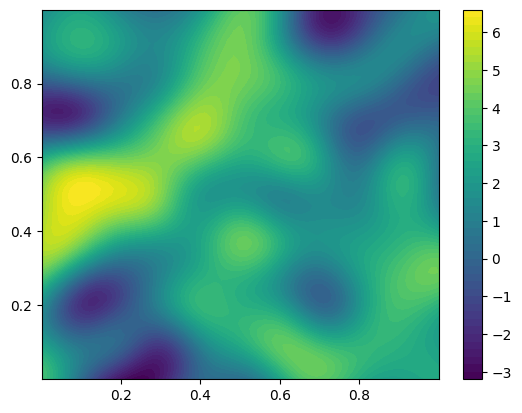

In [31]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), u_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

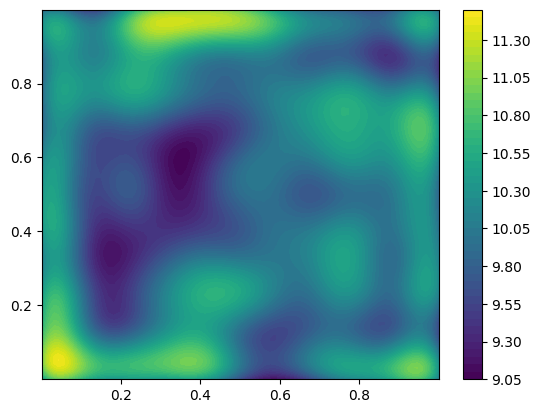

In [18]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), theta_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

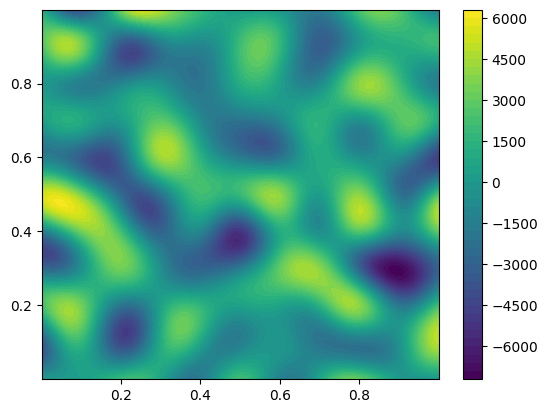

In [19]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), f_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

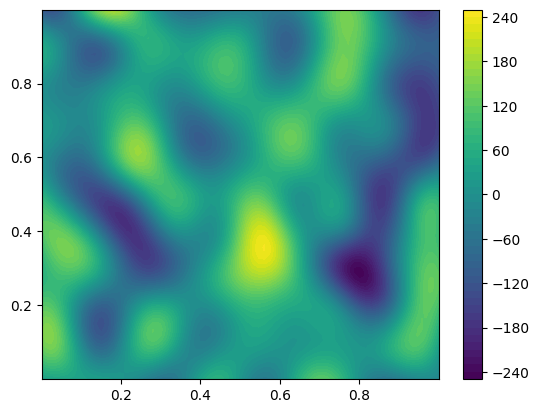

In [20]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), eta_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

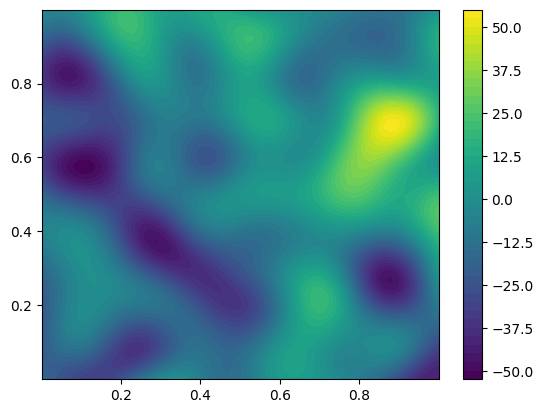

In [21]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), g_data[sample].cpu().numpy(), levels=50)
plt.colorbar()